# Limpieza de datos

## 1. Importación de librerías y datos

Se carga cada conjunto por separado y se crea una copia de trabajo para la limpieza.

In [13]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file()
    and (path / "src" / "appr_project").is_dir()
)
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd

from appr_project.cleaning import (
    detect_history_deviations,
    fila_ab,
    ks_ab,
    proporcion_ab,
)
from appr_project.eda import load_sets

sets = load_sets(ROOT / "data" / "csv")
sets_clean = {name: frame.copy() for name, frame in sets.items()}

## 2. Exclusión de pacientes

Se excluyen todas las filas de cada paciente con una edad registrada menor de 18 años.

In [14]:
for name, frame in sets_clean.items():
    minor_ids = frame.loc[frame["Age"].lt(18), "patient_id"].unique()
    keep = ~frame["patient_id"].isin(minor_ids)
    sets_clean[name] = frame.loc[keep].copy()
    print(f"{name}: {len(minor_ids)} pacientes y {(~keep).sum()} filas excluidas.")

A: 0 pacientes y 0 filas excluidas.
B: 22 pacientes y 749 filas excluidas.


## 3. Exclusión de columnas o variables


### Cobertura por variable en A y B

Las tablas se calculan después de excluir a los pacientes menores de edad y
antes de eliminar columnas. Una observación faltante es una fila sin valor.
Un paciente sin observaciones es aquel que no tiene ningún valor registrado
para esa variable. Cada porcentaje usa como denominador el total de filas o
de pacientes de su conjunto, según corresponda.


In [15]:
def cobertura_por_variable(datos):
    variables = datos.drop(columns=["patient_id", "source_set"])
    observadas = variables.notna()
    por_paciente = observadas.groupby(datos["patient_id"], sort=False).any()

    n_observadas = observadas.sum()
    n_faltantes = len(datos) - n_observadas
    pacientes_con_dato = por_paciente.sum()
    pacientes_sin_dato = len(por_paciente) - pacientes_con_dato

    cobertura = pd.DataFrame({
        "observaciones disponibles": n_observadas,
        "observaciones faltantes": n_faltantes,
        "observaciones faltantes (%)": 100 * n_faltantes / len(datos),
        "pacientes con observaciones": pacientes_con_dato,
        "pacientes sin observaciones": pacientes_sin_dato,
        "pacientes sin observaciones (%)": 100 * pacientes_sin_dato / len(por_paciente),
    }).rename_axis("variable")
    return cobertura.sort_values(
        ["pacientes sin observaciones (%)", "observaciones faltantes (%)"],
        ascending=False,
    )


cobertura_a = cobertura_por_variable(sets_clean["A"])
cobertura_b = cobertura_por_variable(sets_clean["B"])

with pd.option_context("display.max_rows", None):
    print("Conjunto A")
    display(cobertura_a.round(2))
    print("Conjunto B")
    display(cobertura_b.round(2))


Conjunto A


,observaciones disponibles,observaciones faltantes,observaciones faltantes (%),pacientes con observaciones,pacientes sin observaciones,pacientes sin observaciones (%)
variable,,,,,,
EtCO2,0,790215,100.00,0,20336,100.00
TroponinI,965,789250,99.88,489,19847,97.60
Bilirubin_direct,1182,789033,99.85,586,19750,97.12
Fibrinogen,6030,784185,99.24,2567,17769,87.38
Alkalinephos,11532,778683,98.54,5703,14633,71.96
Bilirubin_total,9693,780522,98.77,5770,14566,71.63
AST,11820,778395,98.50,5893,14443,71.02
Lactate,27143,763072,96.57,7733,12603,61.97
SaO2,39160,751055,95.04,7963,12373,60.84


Conjunto B


,observaciones disponibles,observaciones faltantes,observaciones faltantes (%),pacientes con observaciones,pacientes sin observaciones,pacientes sin observaciones (%)
variable,,,,,,
HCO3,1411,759835,99.81,416,19562,97.92
BaseExcess,1764,759482,99.77,558,19420,97.21
Bilirubin_direct,1807,759439,99.76,1470,18508,92.64
Chloride,4687,756559,99.38,1616,18362,91.91
Fibrinogen,4210,757036,99.45,1947,18031,90.25
EtCO2,57590,703656,92.43,3213,16765,83.92
PTT,7387,753859,99.03,4392,15586,78.02
Lactate,14295,746951,98.12,4757,15221,76.19
SaO2,14394,746852,98.11,5121,14857,74.37


### Columnas excluidas

Se conserva `Unit1` como indicador de unidad y se elimina `Unit2`.
Además, se eliminan las variables con un 95 % o más de pacientes sin
observaciones o un 99 % o más de filas faltantes en cualquiera de los
conjuntos A y B. Se utiliza la unión de las columnas identificadas para
conservar el mismo esquema en ambos conjuntos. Los umbrales se aplican
a los porcentajes originales, antes de redondearlos para mostrarlos.


In [16]:
columns_to_drop = {"Unit2"}
for cobertura in (cobertura_a, cobertura_b):
    excluir = (
        cobertura["pacientes sin observaciones (%)"].ge(95)
        | cobertura["observaciones faltantes (%)"].ge(99)
    )
    columns_to_drop.update(cobertura.index[excluir])

columns_to_drop = sorted(columns_to_drop)
sets_clean = {
    name: frame.drop(columns=columns_to_drop)
    for name, frame in sets_clean.items()
}
print("Columnas excluidas:", ", ".join(columns_to_drop))


Columnas excluidas: BaseExcess, Bilirubin_direct, Chloride, EtCO2, Fibrinogen, HCO3, PTT, TroponinI, Unit2


## 4. Corrección de escalas

### FiO2

En A se corrige el 7 de A_003242 a 0,7, de acuerdo con sus observaciones previas, y se deja como faltante el 10 de A_016800. En B se marcan como faltantes los valores mayores que 1. En ambos conjuntos se aplica el mismo tratamiento a los valores menores que 0,21.

In [17]:
fio2_a = sets_clean["A"]
fio2_a.loc[fio2_a["patient_id"].eq("A_003242") & fio2_a["FiO2"].eq(7), "FiO2"] = 0.7
fio2_a.loc[fio2_a["patient_id"].eq("A_016800") & fio2_a["FiO2"].eq(10), "FiO2"] = float("nan")

fio2_b = sets_clean["B"]
fio2_b.loc[fio2_b["FiO2"].gt(1), "FiO2"] = float("nan")

for frame in sets_clean.values():
    frame.loc[frame["FiO2"].lt(0.21), "FiO2"] = float("nan")

### Calcium en B

Se estima la densidad de las mediciones del B original con un núcleo gaussiano y un ancho de suavizado de 0,20. Se busca el mínimo entre 1,8 y 4,0 para localizar el valle que separa el grupo concentrado cerca de 1,2 del resto. El corte depende del suavizado y sirve para separar grupos de valores candidatos; no confirma la unidad ni el tipo de medición.

El listado muestra las mediciones del B original en el intervalo **[2, 3)**. En la copia de trabajo de B, los valores inferiores al corte se sustituyen por faltantes en `Calcium`. Las líneas que los conservarían en `Calcium_low` y añadirían esa columna vacía en A están comentadas: esa transformación aún no se aplica y la columna no se exporta. Los valores originales permanecen disponibles en `sets`.


In [18]:
calcium_original = sets["B"]["Calcium"].dropna()
values, counts = np.unique(calcium_original, return_counts=True)
bandwidth = 0.20

def calcium_density(grid):
    distances = (grid[:, None] - values) / bandwidth
    weights = np.exp(-0.5 * distances**2)
    return (weights @ counts) / (counts.sum() * bandwidth * np.sqrt(2 * np.pi))

valley_grid = np.linspace(1.8, 4.0, 2201)
valley_density = calcium_density(valley_grid)
calcium_cutoff = float(valley_grid[valley_density.argmin()])
print(f"Mínimo de densidad entre 1,8 y 4,0: {calcium_cutoff:.3f}")

between = sets["B"].loc[
    sets["B"]["Calcium"].ge(2) & sets["B"]["Calcium"].lt(3),
    ["patient_id", "ICULOS", "Calcium"],
].sort_values(["Calcium", "patient_id", "ICULOS"])
print(f"Registros en [2, 3): {len(between)}")
print(between.to_string(index=False))

Mínimo de densidad entre 1,8 y 4,0: 2.633
Registros en [2, 3): 18
patient_id  ICULOS  Calcium
  B_105905       8     2.03
  B_105944      12     2.04
  B_105905       4     2.05
  B_115162       4     2.06
  B_102303       3     2.09
  B_107071      38     2.25
  B_105944       4     2.28
  B_117598      96     2.34
  B_114694       2     2.35
  B_103999       7     2.36
  B_115299       4     2.39
  B_103603      13     2.58
  B_109512       6     2.70
  B_111418       2     2.72
  B_107773      32     2.92
  B_114328       2     2.92
  B_110009       5     2.94
  B_111138      28     2.97


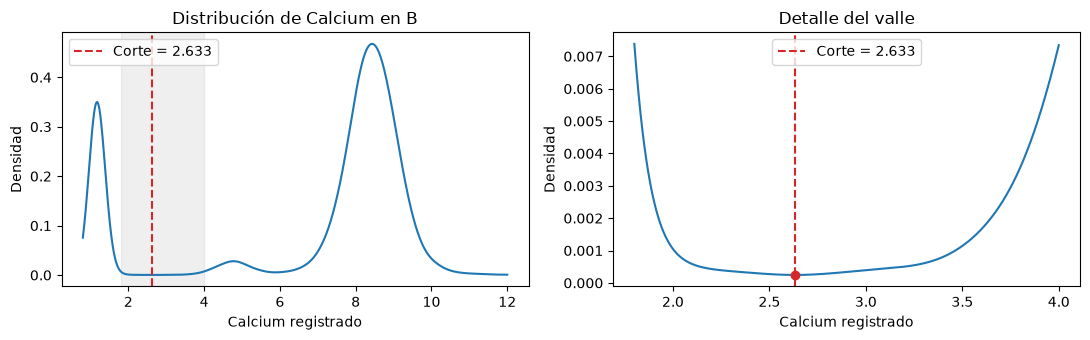

In [19]:
plot_grid = np.linspace(0.8, 12, 1200)
fig, (overview, zoom) = plt.subplots(1, 2, figsize=(11, 3.5))
overview.plot(plot_grid, calcium_density(plot_grid))
overview.axvspan(1.8, 4.0, alpha=0.12, color="gray")
overview.set_title("Distribución de Calcium en B")
zoom.plot(valley_grid, valley_density)
zoom.scatter(calcium_cutoff, valley_density.min(), color="tab:red", zorder=3)
zoom.set_title("Detalle del valle")
for ax in (overview, zoom):
    ax.axvline(calcium_cutoff, color="tab:red", linestyle="--", label=f"Corte = {calcium_cutoff:.3f}")
    ax.set(xlabel="Calcium registrado", ylabel="Densidad")
    ax.legend()
fig.tight_layout()
plt.show()

In [20]:
calcium_b = sets_clean["B"]
low_calcium = calcium_b["Calcium"].lt(calcium_cutoff)
# calcium_b["Calcium_low"] = calcium_b["Calcium"].where(low_calcium)
calcium_b["Calcium"] = calcium_b["Calcium"].mask(low_calcium)
# sets_clean["A"]["Calcium_low"] = float("nan")

### Unidades de trabajo de Lactate y Magnesium

Para A y B se adoptan las siguientes unidades de trabajo a partir de las magnitudes observadas en los CSV originales. Son hipótesis sobre la unidad de almacenamiento. Se interpretan los valores tal como están almacenados, sin aplicar factores de conversión.

- **Lactate: mmol/L.** Las medianas observadas son 1,80 en A y 1,97 en B, magnitudes compatibles con el intervalo de referencia para adultos de 0,5–2,0 mmol/L. PhysioNet publica mg/dL. [Mayo Clinic Laboratories — Lactate, Plasma](https://www.mayocliniclabs.com/test-catalog/overview/601685).
- **Magnesium: mg/dL.** La mediana observada es 2,0 en ambos conjuntos, magnitud compatible con el intervalo de referencia para adultos de 1,7–2,3 mg/dL. PhysioNet publica mmol/dL. [Mayo Clinic Laboratories — Magnesium, Serum](https://www.mayocliniclabs.com/test-catalog/overview/8448).

Los intervalos aportan contexto para interpretar las magnitudes. La unidad efectiva queda pendiente de confirmación con metadatos de origen. [Documentación de PhysioNet](https://physionet.org/content/challenge-2019/1.0.0/).

### HCO3 igual a cero

En los CSV originales se identificaron dos registros con HCO3 igual a cero en A y ninguno en B. Se conserva como referencia el código para listar esos registros y sustituir los ceros por faltantes, pero está comentado y no se ejecuta.


Este tratamiento solo se consideraría si `HCO3` se conserva en el punto 3. Con la selección actual, la columna se elimina y aquí no se modifica ningún dato.


In [21]:
# hco3_ceros = []
# for name, frame in sets_clean.items():
#     zero = frame["HCO3"].eq(0)
#     registros = frame.loc[zero, ["patient_id", "ICULOS", "HCO3"]].copy()
#     registros.insert(0, "conjunto", name)
#     hco3_ceros.append(registros)
#     print(f"{name}: {len(registros)} registros con HCO3 igual a cero.")
#     frame.loc[zero, "HCO3"] = np.nan
# 
# display(pd.concat(hco3_ceros, ignore_index=True))

## 5. Saltos y desviaciones del historial

Se calcula la mediana y la desviación absoluta mediana (MAD) de las mediciones previas del mismo paciente. La ventana limita tanto el número de observaciones como su antigüedad. Un valor fuera de mediana ± k × MAD / 0,6745 se etiqueta como **desviación del historial**. La etiqueta señala un candidato a revisión, no un error confirmado.

Si el valor cruza un límite, la función propone una ponderación entre el límite cruzado y el dato observado. El parámetro alfa es el peso del dato observado: alfa 0 propone recortar al límite y alfa 1 conserva el valor. La referencia usa mediciones originales previas. Los casos con historial insuficiente o MAD cero se omiten, salvo que se configure un margen mínimo positivo para evaluar los casos de MAD cero con historial suficiente. En este notebook solo se calculan las propuestas; no se aplican al conjunto limpio.


### 5.1. Revisión de O2Sat en A

Se usa alfa 0,5 como punto de partida. `desviaciones_o2sat` contiene los registros señalados, con el paciente, la hora, la mediana y MAD previas, los límites y el ajuste propuesto. La línea que asignaría los valores ajustados a `O2Sat` está comentada, por lo que los valores se conservan sin cambios.

`resumen_o2sat` resume las propuestas. Su campo `registros_ajustados` cuenta ajustes propuestos distintos de cero, no modificaciones efectivamente aplicadas. Las líneas que mostrarían ese resumen y la comparación antes/después también están comentadas.


In [26]:
conjunto = "A"
variable = "O2Sat"
alpha = 0.5
frame = sets_clean[conjunto]
antes = frame[variable].copy()

desviaciones_o2sat = detect_history_deviations(
    frame, variable, alpha,
    window=20, min_history=5, max_age_hours=24, k=10, min_margin=None,
)
desviaciones_o2sat.insert(0, "conjunto", conjunto)

if not desviaciones_o2sat.empty:
    posiciones = desviaciones_o2sat["row_position"].to_numpy()
    # frame.iloc[posiciones, frame.columns.get_loc(variable)] = desviaciones_o2sat["adjusted_value"].to_numpy()

display(desviaciones_o2sat.head(20))

,conjunto,row_position,patient_id,ICULOS,variable,original_value,history_n,history_median,history_mad,lower,upper,alpha,adjusted_value,adjustment
0,A,301,A_000008,38.0,O2Sat,89.0,20,99.50,0.50,92.087102,106.912898,0.5,90.543551,1.543551
1,A,1099,A_000024,10.0,O2Sat,89.0,8,97.50,0.50,90.087102,104.912898,0.5,89.543551,0.543551
2,A,1421,A_000032,31.0,O2Sat,79.0,20,98.00,1.00,83.174203,112.825797,0.5,81.087102,2.087102
3,A,2219,A_000056,8.0,O2Sat,91.0,6,97.00,0.25,93.293551,100.706449,0.5,92.146775,1.146775
4,A,3231,A_000087,10.0,O2Sat,91.5,6,99.50,0.50,92.087102,106.912898,0.5,91.793551,0.293551
5,A,3683,A_000100,19.0,O2Sat,91.0,16,99.00,0.25,95.293551,102.706449,0.5,93.146775,2.146775
6,A,4002,A_000108,24.0,O2Sat,94.0,20,99.75,0.25,96.043551,103.456449,0.5,95.021775,1.021775
7,A,4234,A_000114,10.0,O2Sat,81.0,7,97.00,1.00,82.174203,111.825797,0.5,81.587102,0.587102
8,A,4374,A_000117,43.0,O2Sat,53.0,20,94.00,1.00,79.174203,108.825797,0.5,66.087102,13.087102
9,A,4821,A_000131,12.0,O2Sat,96.0,10,99.75,0.25,96.043551,103.456449,0.5,96.021775,0.021775


In [35]:
ajustes = desviaciones_o2sat["adjustment"]
n_observados = antes.count()
resumen_o2sat = pd.DataFrame([{
    "conjunto": conjunto,
    "variable": variable,
    "alpha": alpha,
    "observaciones": n_observados,
    "registros_señalados": len(desviaciones_o2sat),
    "registros_ajustados": int(ajustes.ne(0).sum()),
    "pacientes_señalados": desviaciones_o2sat["patient_id"].nunique(),
    "porcentaje_señalado": 100 * len(desviaciones_o2sat) / n_observados if n_observados else np.nan,
    "ajuste_absoluto_mediano": ajustes.abs().median() if len(ajustes) else np.nan,
    "ajuste_absoluto_máximo": ajustes.abs().max() if len(ajustes) else np.nan,
}])
# display(resumen_o2sat)
# display(pd.DataFrame({"antes": antes.describe(), "después": frame[variable].describe()}))

## 6. Equivalencia entre A y B

Se comparan las distribuciones marginales de los datos limpios, excluyendo el
identificador del paciente y la etiqueta de origen. Para las numéricas se calcula KS y se muestran
los percentiles 5, 25, 50, 75 y 95. Para `Gender`, `Unit1` y `SepsisLabel`
se compara la proporción de unos entre los registros observados. La proporción
de faltantes se compara por separado para cada variable.

Los cálculos ponderan por registro. Para estimar la incertidumbre se remuestrean
pacientes completos por separado en A y B, bajo el supuesto de independencia entre
pacientes. Para KS, una banda bootstrap aproxima la incertidumbre sobre una
cuadrícula de cuantiles. Se evalúan ambos lados de cada corte y se usa la monotonía
de las distribuciones acumuladas para acotar KS entre los cortes.
[Referencia del bootstrap por conglomerados](https://doi.org/10.1111/j.1467-9868.2007.00593.x).

Los márgenes de 5 puntos porcentuales son provisionales y configurables por
variable y medida. Se declara equivalencia si el límite superior del intervalo
aproximado del 95 % queda por debajo del margen, diferencia relevante si el
inferior lo supera, e inconcluso en los demás casos. Los intervalos son por
comparación. La equivalencia marginal global requiere que todas las
comparaciones de valores y faltantes cumplan sus márgenes.


In [22]:
binarias_ab = {"Gender", "Unit1", "SepsisLabel"}
margenes_ab = {"KS": 5.0, "Unos": 5.0, "Faltantes": 5.0}  # En puntos porcentuales.
margenes_por_variable_ab = {}  # Claves (variable, medida).
percentiles_ab = [5, 25, 50, 75, 95]
n_boot_ab = 499
rng_ab = np.random.default_rng(2026)

frames_ab = [sets_clean[nombre] for nombre in ("A", "B")]
pacientes_ab = [pd.factorize(datos["patient_id"])[0] for datos in frames_ab]
pesos_ab = []
for pacientes in pacientes_ab:
    n_pacientes = pacientes.max() + 1
    pesos_ab.append(rng_ab.multinomial(
        n_pacientes, np.full(n_pacientes, 1 / n_pacientes), size=n_boot_ab
    ).astype(np.float32))


In [23]:
filas_ab, cuantiles_ab = [], []
for variable in frames_ab[0].columns.drop(["patient_id", "source_set"]):
    columnas = [datos[variable].to_numpy() for datos in frames_ab]
    validos = [~pd.isna(valores) for valores in columnas]
    observaciones = [valores[valido] for valores, valido in zip(columnas, validos)]

    faltantes = proporcion_ab(
        [~valido for valido in validos], [np.ones_like(valido) for valido in validos],
     pacientes_ab=pacientes_ab, pesos_ab=pesos_ab)
    filas_ab.append(fila_ab(variable, "Faltantes", *faltantes, margenes_ab=margenes_ab, margenes_por_variable_ab=margenes_por_variable_ab))

    if variable in binarias_ab:
        unos = proporcion_ab([valores == 1 for valores in columnas], validos, pacientes_ab=pacientes_ab, pesos_ab=pesos_ab)
        filas_ab.append(fila_ab(variable, "Unos", *unos, margenes_ab=margenes_ab, margenes_por_variable_ab=margenes_por_variable_ab))
    else:
        filas_ab.append(fila_ab(variable, "KS", *ks_ab(observaciones, validos, pacientes_ab=pacientes_ab, pesos_ab=pesos_ab), margenes_ab=margenes_ab, margenes_por_variable_ab=margenes_por_variable_ab))
        cuantiles = [
            np.percentile(valores, percentiles_ab) if valores.size
            else np.full(len(percentiles_ab), np.nan)
            for valores in observaciones
        ]
        for percentil, a, b in zip(percentiles_ab, *cuantiles):
            cuantiles_ab.append({"variable": variable, "percentil": percentil, "A": a, "B": b, "A - B": a - b})

equivalencia_ab = pd.DataFrame(filas_ab).sort_values(
    ["medida", "distancia (pp)"], ascending=[True, False]
).reset_index(drop=True)
percentiles_numericas_ab = pd.DataFrame(cuantiles_ab)
print(equivalencia_ab.groupby(["medida", "resultado"]).size().unstack(fill_value=0))
print(
    "Equivalencia marginal global demostrada."
    if equivalencia_ab["resultado"].eq("Equivalente").all()
    else "Equivalencia marginal global no demostrada."
)
with pd.option_context("display.max_rows", None):
    faltantes_ab = equivalencia_ab["medida"].eq("Faltantes")
    display(equivalencia_ab.loc[faltantes_ab].reset_index(drop=True).round(3))
    ks_ab_filas = equivalencia_ab["medida"].eq("KS")
    tabla_ks_ab = equivalencia_ab.loc[ks_ab_filas].drop(columns=["A (%)", "B (%)"])
    display(tabla_ks_ab.reset_index(drop=True).round(3))
    unos_ab = equivalencia_ab["medida"].eq("Unos")
    display(equivalencia_ab.loc[unos_ab].reset_index(drop=True).round(3))
display(percentiles_numericas_ab.pivot(
    index="variable", columns="percentil", values=["A", "B", "A - B"]
).round(3))


resultado  Diferencia relevante  Equivalente  Inconcluso
medida                                                  
Faltantes                     8           24           0
KS                           19            4           6
Unos                          0            3           0
Equivalencia marginal global no demostrada.


,variable,medida,A (%),B (%),distancia (pp),inferior 95 % (pp),superior 95 % (pp),margen (pp),resultado
0,DBP,Faltantes,48.126,13.943,34.183,33.516,34.850,5.0,Diferencia relevante
1,Unit1,Faltantes,48.868,29.617,19.251,18.202,20.300,5.0,Diferencia relevante
2,FiO2,Faltantes,85.848,97.750,11.903,11.654,12.152,5.0,Diferencia relevante
3,Resp,Faltantes,9.777,21.140,11.363,11.000,11.726,5.0,Diferencia relevante
4,Glucose,Faltantes,87.768,77.842,9.927,9.614,10.240,5.0,Diferencia relevante
5,pH,Faltantes,88.533,97.774,9.241,9.034,9.448,5.0,Diferencia relevante
6,PaCO2,Faltantes,91.232,97.766,6.535,6.359,6.710,5.0,Diferencia relevante
7,Hct,Faltantes,88.224,94.177,5.954,5.821,6.087,5.0,Diferencia relevante
8,MAP,Faltantes,10.232,14.751,4.519,4.214,4.823,5.0,Equivalente
9,HR,Faltantes,7.743,12.102,4.359,4.085,4.632,5.0,Equivalente


,variable,medida,distancia (pp),inferior 95 % (pp),superior 95 % (pp),margen (pp),resultado
0,HospAdmTime,KS,31.396,29.551,33.823,5.0,Diferencia relevante
1,SaO2,KS,30.537,28.160,32.915,5.0,Diferencia relevante
2,AST,KS,20.924,17.471,24.755,5.0,Diferencia relevante
3,MAP,KS,19.585,18.628,20.668,5.0,Diferencia relevante
4,DBP,KS,19.409,18.264,20.729,5.0,Diferencia relevante
5,Hgb,KS,17.202,15.718,18.704,5.0,Diferencia relevante
6,FiO2,KS,15.074,12.794,17.411,5.0,Diferencia relevante
7,Creatinine,KS,12.113,10.442,13.784,5.0,Diferencia relevante
8,Bilirubin_total,KS,11.670,8.347,15.766,5.0,Diferencia relevante
9,WBC,KS,11.582,9.976,13.827,5.0,Diferencia relevante


,variable,medida,A (%),B (%),distancia (pp),inferior 95 % (pp),superior 95 % (pp),margen (pp),resultado
0,Gender,Unos,57.772,54.021,3.751,2.672,4.831,5.0,Equivalente
1,Unit1,Unos,50.710,48.881,1.829,0.463,3.196,5.0,Equivalente
2,SepsisLabel,Unos,2.169,1.414,0.755,0.633,0.876,5.0,Equivalente


A                                        B          \
percentil            5       25      50      75       95      5       25   
variable                                                                   
AST               15.00   28.00   57.00  180.00  1728.15   13.00   20.00   
Age               31.39   52.74   65.25   75.89    85.04   30.00   50.00   
Alkalinephos      37.00   56.00   78.00  119.00   300.00   34.00   52.00   
BUN                7.00   12.00   18.00   29.00    66.00    6.00   11.00   
Bilirubin_total    0.20    0.50    0.90    2.20    11.60    0.30    0.60   
Calcium            7.10    7.80    8.30    8.80     9.50    6.70    8.00   
Creatinine         0.50    0.70    0.90    1.40     4.40    0.52    0.75   
DBP               42.50   51.00   58.50   67.00    82.00   46.00   56.00   
FiO2               0.35    0.40    0.50    0.55     1.00    0.21    0.40   
Glucose           79.00  104.00  124.00  150.00   218.00   83.00  108.00   
HR                60.00   73.00   84.00   96.00   114.00   58.00   71.00   
Hct               23.50   27.40   30.20   33.50    39.30   21.30   26.00   
Hgb                8.00    9.40   10.40   11.60    13.70    7.10    8.50   
HospAdmTime     -257.30  -38.09   -2.60   -0.02    -0.01 -266.64  -56.25   
ICULOS             3.00   11.00   21.00   35.00    62.00    2.00   10.00   
Lactate            0.80    1.20    1.80    2.80     6.40    0.86    1.33   
MAP               58.00   68.00   77.00   87.33   105.00   63.00   74.50   
Magnesium          1.50    1.80    2.00    2.20     2.70    1.50    1.80   
O2Sat             93.00   96.00   98.00   99.50   100.00   92.00   96.00   
PaCO2             29.00   36.00   40.00   45.00    57.00   28.00   34.70   
Phosphate          1.80    2.70    3.40    4.20     6.20    1.70    2.60   
Platelets         67.90  127.00  181.00  247.00   395.00   63.00  126.00   
Potassium          3.30    3.80    4.10    4.50     5.20    3.20    3.70   
Resp              11.00   15.00   18.00   22.00    28.00   12.00   16.00   
SBP               91.00  105.00  118.50  134.00   160.00   91.00  109.00   
SaO2              62.00   93.00   97.00   98.00    99.00   90.80   95.70   
Temp              35.78   36.56   37.06   37.55    38.22   35.80   36.50   
WBC                4.70    8.00   10.80   14.30    22.10    4.30    7.00   
pH                 7.26    7.34    7.39    7.43     7.48    7.22    7.32   

                                         A - B                                 
percentil            50      75      95     5      25     50      75       95  
variable                                                                       
AST               32.00   72.00  651.00   2.00   8.00  25.00  108.00  1077.15  
Age               63.00   72.00   85.00   1.39   2.74   2.25    3.89     0.04  
Alkalinephos      70.00  101.00  215.00   3.00   4.00   8.00   18.00    85.00  
BUN               17.00   28.00   63.00   1.00   1.00   1.00    1.00     3.00  
Bilirubin_total    0.80    1.40    5.10  -0.10  -0.10   0.10    0.80     6.50  
Calcium            8.40    8.90    9.60   0.40  -0.20  -0.10   -0.10    -0.10  
Creatinine         0.99    1.51    5.67  -0.02  -0.05  -0.09   -0.11    -1.27  
DBP               65.00   74.00   91.00  -3.50  -5.00  -6.50   -7.00    -9.00  
FiO2               0.40    0.60    1.00   0.14   0.00   0.10   -0.05     0.00  
Glucose          128.00  155.00  236.00  -4.00  -4.00  -4.00   -5.00   -18.00  
HR                83.00   95.00  115.00   2.00   2.00   1.00    1.00    -1.00  
Hct               30.50   35.70   42.30   2.20   1.40  -0.30   -2.20    -3.00  
Hgb                9.90   11.70   14.20   0.90   0.90   0.50   -0.10    -0.50  
HospAdmTime       -8.96   -3.10    0.00   9.34  18.16   6.36    3.08    -0.01  
ICULOS            20.00   34.00   64.00   1.00   1.00   1.00    1.00    -2.00  
Lactate            1.97    3.43    8.73  -0.06  -0.13  -0.17   -0.63    -2.33  
MAP               84.00   96.00  116.00  -5.00  -6.50  -7.00   -8.67 

## 7. Resumen de los cambios aplicados

Se resumen las exclusiones y los cambios efectivos respecto de los datos originales. Los valores corregidos y los nuevos faltantes se cuentan únicamente en las filas y columnas conservadas; no incluyen los datos eliminados al excluir pacientes o columnas. Los nuevos faltantes corresponden a las reglas de `FiO2` y `Calcium`; los faltantes no se imputan. No se crea `Calcium_low` ni se aplican los ajustes propuestos para `O2Sat` o el tratamiento comentado de `HCO3`.


In [27]:
resumen_cambios = []
for nombre, limpio in sets_clean.items():
    original = sets[nombre]
    corregidos = 0
    nuevos_faltantes = 0
    for columna in limpio.columns.intersection(original.columns):
        previo = original.loc[limpio.index, columna]
        actual = limpio[columna]
        nuevos_faltantes += int((previo.notna() & actual.isna()).sum())
        corregidos += int((previo.notna() & actual.notna() & previo.ne(actual)).sum())
    resumen_cambios.append({
        "conjunto": nombre,
        "pacientes excluidos": original["patient_id"].nunique() - limpio["patient_id"].nunique(),
        "filas excluidas": len(original) - len(limpio),
        "pacientes finales": limpio["patient_id"].nunique(),
        "filas finales": len(limpio),
        "valores corregidos": corregidos,
        "nuevos faltantes": nuevos_faltantes,
    })

print("Columnas excluidas:", ", ".join(columns_to_drop))
display(pd.DataFrame(resumen_cambios).set_index("conjunto"))


Columnas excluidas: BaseExcess, Bilirubin_direct, Chloride, EtCO2, Fibrinogen, HCO3, PTT, TroponinI, Unit2


,pacientes excluidos,filas excluidas,pacientes finales,filas finales,valores corregidos,nuevos faltantes
conjunto,,,,,,
A,0,0,20336,790215,1,320
B,22,749,19978,761246,0,9964


## 8. Partición train–test por paciente

Se divide cada conjunto por separado en aproximadamente un **80 % de pacientes para entrenamiento** y un **20 % para prueba**, con semilla fija `2026`. Se estratifica según si el paciente tiene al menos una hora con `SepsisLabel = 1`, para mantener aproximadamente la proporción de pacientes positivos. El número de pacientes de prueba se redondea al entero más cercano dentro de cada estrato.

Todas las horas de un paciente quedan en una sola partición. Se conservan el orden original de las filas, las columnas y los valores faltantes. Los porcentajes por filas pueden diferir del 80/20 porque las historias tienen distinta longitud. La etiqueta por paciente solo se usa para estratificar; no se añade como predictor.

La validación y el ajuste de hiperparámetros se realizarán dentro del conjunto de entrenamiento; el conjunto de prueba se reserva para la evaluación final. Para entrenar con A+B se combinarán únicamente las particiones de entrenamiento, usando estos mismos pacientes de prueba para comparar los modelos. La selección por cobertura y el corte de calcio se mantienen tal como se definieron antes de esta partición.


In [28]:
test_fraction = 0.20
split_seed = 2026
sets_split = {"train": {}, "test": {}}
resumen_particiones = []

for nombre, limpio in sets_clean.items():
    pacientes = limpio.groupby("patient_id", sort=True)["SepsisLabel"].max()
    rng_split = np.random.default_rng(split_seed)
    ids_test = []
    for etiqueta, estrato in pacientes.groupby(pacientes, sort=True):
        ids = estrato.index.to_numpy()
        n_test = int(round(test_fraction * len(ids)))
        ids_test.extend(rng_split.permutation(ids)[:n_test])

    es_test = limpio["patient_id"].isin(ids_test)
    sets_split["train"][nombre] = limpio.loc[~es_test].copy()
    sets_split["test"][nombre] = limpio.loc[es_test].copy()

    for particion in ("train", "test"):
        datos = sets_split[particion][nombre]
        etiquetas = datos.groupby("patient_id")["SepsisLabel"].max()
        resumen_particiones.append({
            "conjunto": nombre,
            "partición": particion,
            "pacientes": len(etiquetas),
            "pacientes (%)": 100 * len(etiquetas) / len(pacientes),
            "pacientes positivos": int(etiquetas.eq(1).sum()),
            "pacientes positivos (%)": 100 * etiquetas.eq(1).mean(),
            "filas": len(datos),
        })

display(pd.DataFrame(resumen_particiones).set_index(["conjunto", "partición"]).round(2))


pacientes  pacientes (%)  pacientes positivos  \
conjunto partición                                                  
A        train          16269           80.0                 1432   
         test            4067           20.0                  358   
B        train          15982           80.0                  912   
         test            3996           20.0                  228   

                    pacientes positivos (%)   filas  
conjunto partición                                   
A        train                         8.80  631031  
         test                          8.80  159184  
B        train                         5.71  607917  
         test                          5.71  153329

## Exportación de las particiones limpias

Se exportan cuatro archivos con el mismo esquema: `data/processed/train/set_A_clean.csv`, `data/processed/train/set_B_clean.csv`, `data/processed/test/set_A_clean.csv` y `data/processed/test/set_B_clean.csv`. Cada archivo contiene todas las filas de los pacientes asignados a esa partición. Esta celda no actualiza los CSV completos de ejecuciones anteriores en la raíz de `processed/`.


In [ ]:
output_dir = ROOT / "data" / "processed"

for particion, conjuntos in sets_split.items():
    partition_dir = output_dir / particion
    partition_dir.mkdir(parents=True, exist_ok=True)
    for name, frame in conjuntos.items():
        output_path = partition_dir / f"set_{name}_clean.csv"
        frame.to_csv(output_path, index=False)
        print(f"{output_path.relative_to(ROOT)}: {len(frame)} filas, "
              f"{frame['patient_id'].nunique()} pacientes y {len(frame.columns)} columnas.")
